# Telco Customer Churn – Data & EDA
**Branch:** `feature/churn-model`

Run once in terminal before starting:
```bash
git checkout -b feature/churn-model
```

## 1. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')  # Kaggle download, same folder

## 2. Data checks

In [2]:
print('Shape:', df.shape)
print('\nDtypes:\n', df.dtypes)
# TotalCharges comes as object because of blank strings -> fix
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('\nMissing values:\n', df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Duplicate customerID:', df['customerID'].duplicated().sum())
print('\nClass balance:\n', df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))

Shape: (7043, 21)

Dtypes:
 customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
 TotalCharges    11
dtype: int64

Duplicate rows: 0
Duplicate customerID: 0

Class balance:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Observations to note:** 7043 rows x 21 cols; `TotalCharges` has 11 blanks (new customers with tenure = 0); no duplicates; churn is imbalanced (~26.5% Yes / 73.5% No).

## 3. Hold-out test set (20%) – done BEFORE any EDA
Stratified on target so class ratio stays same. Test set is saved to disk and **not touched until the final evaluation step**.

In [3]:
df['Churn'] = df['Churn'].map({'No':0,'Yes':1})
X = df.drop(columns=['Churn','customerID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

X_test.assign(Churn=y_test).to_csv('test_holdout.csv', index=False)  # locked away
del X_test, y_test

train = X_train.assign(Churn=y_train)   # all EDA uses only this
print('Train shape:', train.shape, '| churn rate:', round(train['Churn'].mean(),3))

Train shape: (5634, 20) | churn rate: 0.265


## 4. EDA (train data only) – 5 charts

C:\Users\Admin\AppData\Local\Temp\ipykernel_20964\3250296503.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=r.index, y=r.values, ax=ax, palette='Blues')


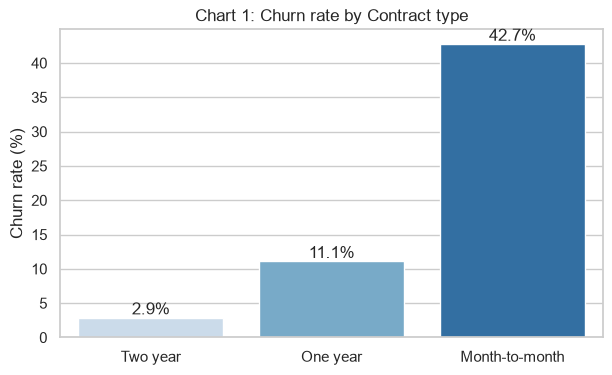

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
r = train.groupby('Contract')['Churn'].mean().mul(100).sort_values()
sns.barplot(x=r.index, y=r.values, ax=ax, palette='Blues')
for i,v in enumerate(r.values): ax.text(i, v+0.5, f'{v:.1f}%', ha='center')
ax.set(title='Chart 1: Churn rate by Contract type', ylabel='Churn rate (%)', xlabel='')
plt.show()

month-to-month customers churn at a much higher rate (~40%+). customers on 1-year and 2-year contracts churn far less.

churn rate by contract type

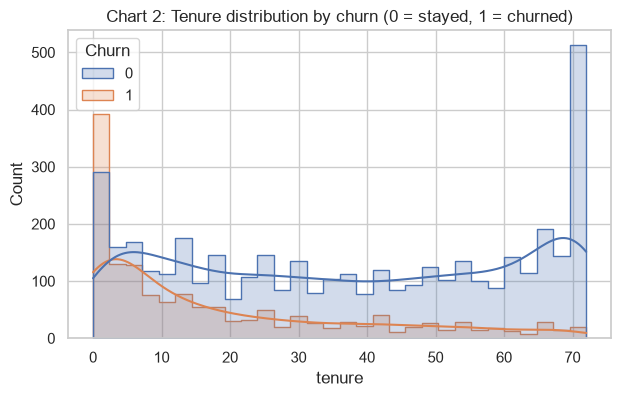

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(data=train, x='tenure', hue='Churn', bins=30, kde=True, element='step', ax=ax)
ax.set(title='Chart 2: Tenure distribution by churn (0 = stayed, 1 = churned)')
plt.show()

churned customers are mostly new, with the highest churn in the first 12 months. customers with longer tenure tend to stay

C:\Users\Admin\AppData\Local\Temp\ipykernel_20964\1323180016.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Churn', y='MonthlyCharges', ax=ax, palette='Set2')


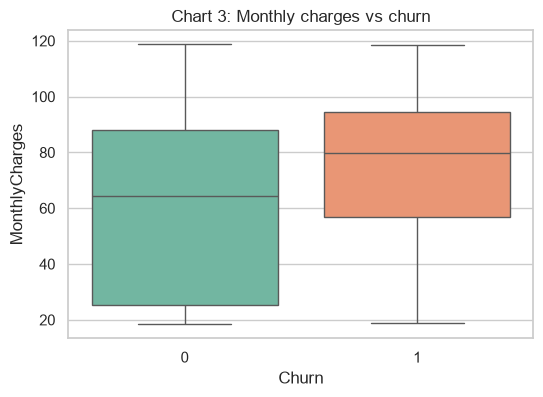

In [6]:
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=train, x='Churn', y='MonthlyCharges', ax=ax, palette='Set2')
ax.set(title='Chart 3: Monthly charges vs churn')
plt.show()

Customers who churned pay higher monthly charges on average than customers who stayed.


C:\Users\Admin\AppData\Local\Temp\ipykernel_20964\3568769109.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=r.index, y=r.values, ax=ax, palette='Oranges')


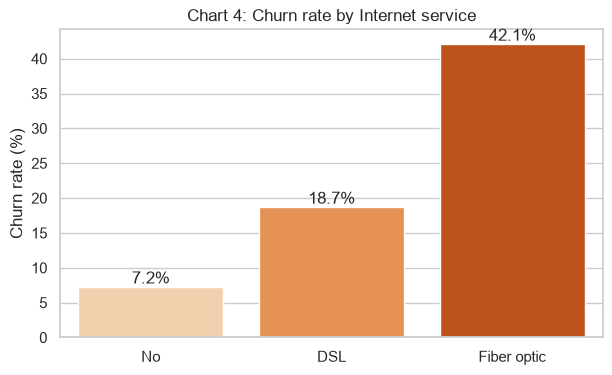

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
r = train.groupby('InternetService')['Churn'].mean().mul(100).sort_values()
sns.barplot(x=r.index, y=r.values, ax=ax, palette='Oranges')
for i,v in enumerate(r.values): ax.text(i, v+0.5, f'{v:.1f}%', ha='center')
ax.set(title='Chart 4: Churn rate by Internet service', ylabel='Churn rate (%)', xlabel='')
plt.show()

Fibre optic customers churn more than DSL customers and customers with no internet service.

C:\Users\Admin\AppData\Local\Temp\ipykernel_20964\780834580.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=r.index, x=r.values, ax=ax, palette='Greens')


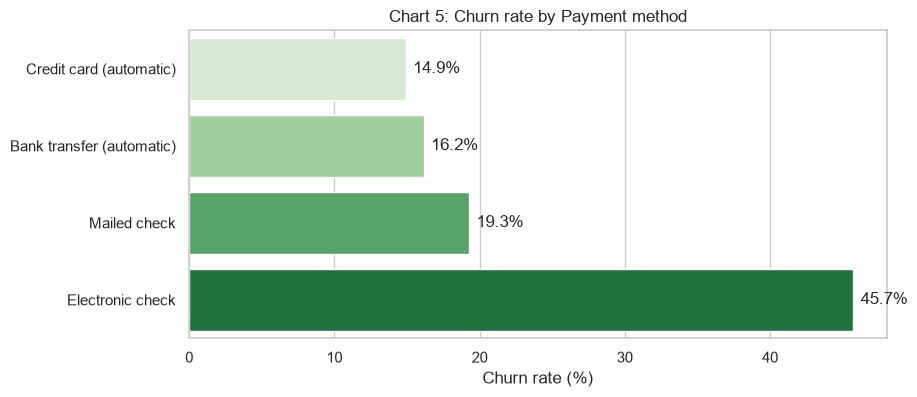

In [8]:
fig, ax = plt.subplots(figsize=(9,4))
r = train.groupby('PaymentMethod')['Churn'].mean().mul(100).sort_values()
sns.barplot(y=r.index, x=r.values, ax=ax, palette='Greens')
for i,v in enumerate(r.values): ax.text(v+0.5, i, f'{v:.1f}%', va='center')
ax.set(title='Chart 5: Churn rate by Payment method', xlabel='Churn rate (%)', ylabel='')
plt.show()

Customers paying by electronic check have the highest churn rate. Customers on automatic payments (bank transfer or credit card) churn less.


**Key takeaways (verify against your charts):**
- Month-to-month contracts churn far more than 1-year / 2-year contracts.
- Churners are mostly low-tenure customers (first ~12 months).
- Churners pay higher monthly charges on average.
- Fibre optic users churn more than DSL / no internet.
- Electronic check users churn the most.

## 5. Assumptions
1. Each row = one unique customer (no duplicates, so no leakage across the split).
2. Blank `TotalCharges` = customers with tenure 0 → will impute with 0 / median inside the pipeline (fit on train only).
3. `customerID` has no predictive value → dropped.
4. The dataset is a representative snapshot; future customers behave similarly (no drift).
5. Preprocessing (imputing, scaling, encoding) will be fitted **only on train** to avoid leakage.
6. Missing a churner (false negative) costs more than a wrongly flagged loyal customer (retention offer is cheap).

## 6. Metric to optimise: **ROC-AUC**
- Churn is imbalanced (~26.5%), so accuracy is misleading (predicting "No" always gives ~73%).
- ROC-AUC is threshold-independent and measures how well the model *ranks* risky customers above safe ones — useful since the business will target the top-N risky customers.
- Used for model selection / CV. After that, I'll tune the decision threshold and report **F1, precision and recall** for the churn class as secondary metrics (since recall matters per assumption 6).